# Tópico 2 - Transformada de Fourier em Tempo Discreto (DTFT)

## Visão Geral e Objetivos
Neste notebook, investigamos a **Transformada de Fourier em Tempo Discreto (DTFT)** aplicada a sequências discretas determinísticas. Os principais objetivos são:
1. **Representação no Domínio da Frequência**: Avaliar a definição contínua da DTFT $X(e^{j\omega}) = \sum_{n=-\infty}^{+\infty} x[n] e^{-j\omega n}$ em uma grade densa de frequências angulares $\omega \in [-\pi, \pi]$.
2. **Análise de Magnitude e Fase**: Extrair e interpretar graficamente o espectro de magnitude $|X(e^{j\omega})|$ e o espectro de fase $\angle X(e^{j\omega})$.
3. **Comparação Domínio do Tempo vs. Frequência**: Observar a transição entre um sinal finito no tempo (pulso retangular) e seu comportamento espectral (função do tipo sinc periódica).
4. **Gerenciamento de Gráficos**: Exportar os gráficos gerados diretamente para arquivos de imagem no diretório local.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Criar/Garantir o diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Definição do Sinal no Domínio do Tempo

Para a análise espectral, selecionamos um pulso retangular discreto finito de comprimento $N_1 = 8$ amostras, definido por:
$$x[n] = \begin{cases} 1, & 0 \le n < N_1 \\ 0, & \text{caso contrário} \end{cases}$$

Abaixo, construímos a sequência temporal em um intervalo de amostragem $n \in [-5, 15]$.

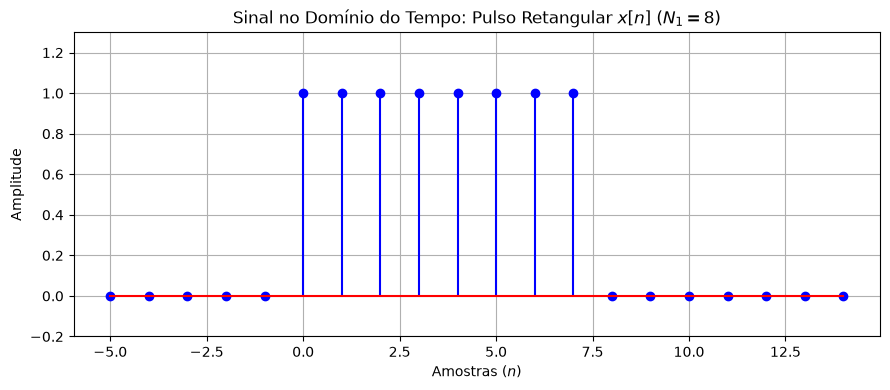

In [2]:
# Intervalo discreto de amostragem
n = np.arange(-5, 15)

# Comprimento do pulso retangular
N1 = 8

# Definição do pulso retangular x[n]
x = np.where((n >= 0) & (n < N1), 1.0, 0.0)

# Plotagem do sinal no domínio do tempo
fig1, ax1 = plt.subplots(figsize=(9, 4))
ax1.stem(n, x, linefmt='b-', markerfmt='bo', basefmt='r-')
ax1.set_title(r'Sinal no Domínio do Tempo: Pulso Retangular $x[n]$ ($N_1 = 8$)')
ax1.set_xlabel('Amostras ($n$)')
ax1.set_ylabel('Amplitude')
ax1.set_ylim(-0.2, 1.3)
ax1.grid(True)

plt.tight_layout()

# Salvar gráfico no diretório corrente
fig1.savefig("grafico_sinal_tempo_dtft.png")
plt.show()

## 2. Cálculo Numérico da DTFT e Plotagem do Espectro

A DTFT de $x[n]$ é dada analiticamente por:
$$X(e^{j\omega}) = \sum_{n=-\infty}^{+\infty} x[n] e^{-j\omega n}$$

Para o pulso retangular de $N_1$ pontos, a DTFT resulta em uma função de razão de senos (sinc discreta):
$$X(e^{j\omega}) = e^{-j\omega \frac{N_1 - 1}{2}} \cdot \frac{\sin(\omega N_1 / 2)}{\sin(\omega / 2)}$$

Abaixo, calculamos $X(e^{j\omega})$ numericamente avaliando a somatório sobre uma grade densa com 1000 pontos no intervalo de frequência angular contínua $-\pi \le \omega \le \pi$.

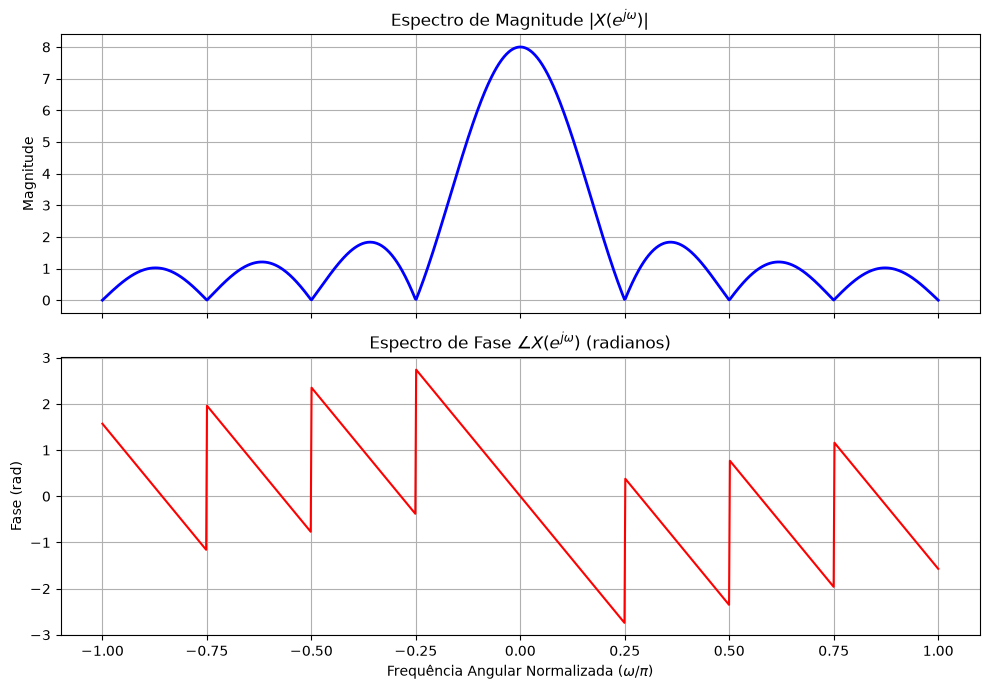

In [3]:
# Grade densa de frequência angular discreta w no intervalo [-pi, pi]
w = np.linspace(-np.pi, np.pi, 1000)

# Cálculo numérico da DTFT por definição via produto matricial/outer
X_dtft = np.sum(x[:, None] * np.exp(-1j * np.outer(n, w)), axis=0)

# Extração de Magnitude e Fase
magnitude = np.abs(X_dtft)
fase = np.angle(X_dtft)

# Plotagem em 2 subplots (Magnitude e Fase)
fig2, (ax_mag, ax_fase) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Subplot 1: Espectro de Magnitude
ax_mag.plot(w / np.pi, magnitude, 'b-', linewidth=2)
ax_mag.set_title(r'Espectro de Magnitude $|X(e^{j\omega})|$')
ax_mag.set_ylabel('Magnitude')
ax_mag.grid(True)

# Subplot 2: Espectro de Fase
ax_fase.plot(w / np.pi, fase, 'r-', linewidth=1.5)
ax_fase.set_title(r'Espectro de Fase $\angle X(e^{j\omega})$ (radianos)')
ax_fase.set_xlabel(r'Frequência Angular Normalizada ($\omega / \pi$)')
ax_fase.set_ylabel('Fase (rad)')
ax_fase.grid(True)

plt.tight_layout()

# Salvar gráfico no diretório corrente
fig2.savefig("grafico_dtft_magnitude_fase.png")
plt.show()

## 3. Síntese dos Resultados da DTFT
- **Periodicidade em $\omega$**: A DTFT é inerentemente periódica com período $2\pi$.
- **Lóbulo Principal e Secundários**: O pulso retangular no tempo se transforma em uma resposta de magnitude em formato de lóbulo sinc no domínio da frequência. O lóbulo principal tem amplitude máxima igual a $N_1 = 8$ em $\omega = 0$.
- **Transições de Fase**: As descontinuidades de fase de $\pi$ radianos coincidem exatamente com os cruzamentos por zero da magnitude do espectro.